# [GSE151227](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE151227)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2021-03-23
> - Modified: 2025-05-17

# 1. Experimental Design

> CRISPR-GEMM pooled mutagenic screening identifies KMT2D as a major modulator of immune checkpoint blockade.
> - Guangchuan Wang, Ryan D. Chow, Lvyun Zhu, Zhigang Bai, Lupeng Ye, Feifei Zhang, Paul A. Renauer, Matthew B. Dong, Xiaoyun Dai, Xiaoya Zhang, Yaying Du, Yujing Cheng, Leilei Niu, Zhiyuan Chu, Kristin Kim, Cun Liao, Paul Clark, Youssef Errami, Sidi Chen; CRISPR-GEMM Pooled Mutagenic Screening Identifies KMT2D as a Major Modulator of Immune Checkpoint Blockade. Cancer Discov 1 December 2020; 10 (12): 1912–1933. https://doi.org/10.1158/2159-8290.CD-19-1448.
> - ATAC-seq
> - mm10

| Sample | Organism | Source | Genotype | Treatment | Replicate |
| - | - | - | - | - | - |
| WT-DMSO | Mus musculus | Liver tumor cells | Wild Type | DMSO | rep1~3 |
| KD-DMSO | Mus musculus | Liver tumor cells | Kmt2d KD | DMSO | rep1~3 |
| WT-IFNG | Mus musculus | Liver tumor cells | Wild Type | IFNG | rep1~3 |
| KD-IFNG | Mus musculus | Liver tumor cells | Kmt2d KD | IFNG | rep1~3 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(ggpubr))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/atacseq_Mm_LiverCancerCell_Kmt2d_GSE151227"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
blacklist_file <- "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"

suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm10))
genome <- BSgenome.Mmusculus.UCSC.mm10

In [3]:
# load reference gene anntotion
gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


# 2. Data Import

## 1). narrowPeak Import

In [4]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R")

In [5]:
peaks_files <- file.path(data_dir, "04_output_atacseq", "05_peaks") |>
    list.files(pattern = "\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub(
        "MA1L_(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

In [6]:
peaks_list <- lapply(
    peaks_files, load_peaks, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

## 2). Import bigwig

In [7]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_bigwig.R")

In [8]:
signals_files <- file.path(data_dir, "04_output_atacseq", "07_bigwig") |>
    list.files(pattern = ".bw$", full.names = TRUE) |>
    set_names(~ sub("MA1L_(.*)\\.bw$", "\\1", basename(.x)))

In [9]:
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

In [10]:
coldata <- data.frame(sample = names(signals_files)) |>
    separate(
        sample, into = c("Genotype", "Treatment", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Genotype = factor(Genotype, levels = c("Control", "sgKmt2d")),
        Treatment = factor(Treatment, levels = c("DMSO", "IFNG")),
        Group = forcats::fct_cross(Genotype, Treatment, sep = "_"),
        Replicate = factor(Replicate)) |>
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Genotype,Treatment,Replicate,Group
,<fct>,<fct>,<fct>,<fct>
Control_DMSO_rep1,Control,DMSO,rep1,Control_DMSO
Control_DMSO_rep2,Control,DMSO,rep2,Control_DMSO
Control_DMSO_rep3,Control,DMSO,rep3,Control_DMSO
Control_IFNG_rep1,Control,IFNG,rep1,Control_IFNG
Control_IFNG_rep2,Control,IFNG,rep2,Control_IFNG
Control_IFNG_rep3,Control,IFNG,rep3,Control_IFNG
sgKmt2d_DMSO_rep1,sgKmt2d,DMSO,rep1,sgKmt2d_DMSO
sgKmt2d_DMSO_rep2,sgKmt2d,DMSO,rep2,sgKmt2d_DMSO
sgKmt2d_DMSO_rep3,sgKmt2d,DMSO,rep3,sgKmt2d_DMSO


In [11]:
peaks_list <- peaks_list[rownames(coldata)]
signals_list <- signals_list[rownames(coldata)]

# 3. Evaluate Library Quality

## 1). Mapping Statistics

| Sample Name | Raw Reads (M) | Clean Reads (M) | Mapped Reads (M) | Mapping Rate | Duplication Rate | Filter Mapped Reads (M) | Filter Mapping Rate | Fragment Length | Number of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - | - | - | - |

## 2). Fragment Size Distribution

In [12]:
fragment_size <- file.path(
    data_dir, "04_output_atacseq", "01_stats", "fragment_size.tsv") |>
    read.table(header = TRUE, sep = "\t") |>
    mutate(Sample = sub("MA1L_(.*)", "\\1", Sample)) |>
    left_join(coldata |> rownames_to_column("Sample"), by = "Sample") |>
    group_by(Sample) |>
    mutate(Freq = Occurrences / sum(Occurrences)) |>
    ungroup()

In [13]:
fragment_size_summary <- fragment_size |>
    group_by(Sample) |>
    summarise(
        mean = matrixStats::weightedMean(
            Size, w = Occurrences, na.rm = TRUE),
        mean_trim_1pct = {
            q_low <- Hmisc::wtd.quantile(
                Size, Occurrences, probs = 0.01, na.rm = TRUE)
            q_high <- Hmisc::wtd.quantile(
                Size, Occurrences, probs = 0.99, na.rm = TRUE)
            idx <- Size >= q_low & Size <= q_high
            matrixStats::weightedMean(
                Size[idx], w = Occurrences[idx], na.rm = TRUE)},
        median = matrixStats::weightedMedian(
            Size, w = Occurrences, na.rm = TRUE)
    )

message(
    "Mean of fragment size: ", round(mean(
        fragment_size_summary$mean), 0),
    " (1% trimmed: ", round(mean(
        fragment_size_summary$mean_trim_1pct), 0), ")")
message(
    "Median of fragment size: ", round(mean(
        fragment_size_summary$median), 0))

Mean of fragment size: 194 (1% trimmed: 189)

Median of fragment size: 157



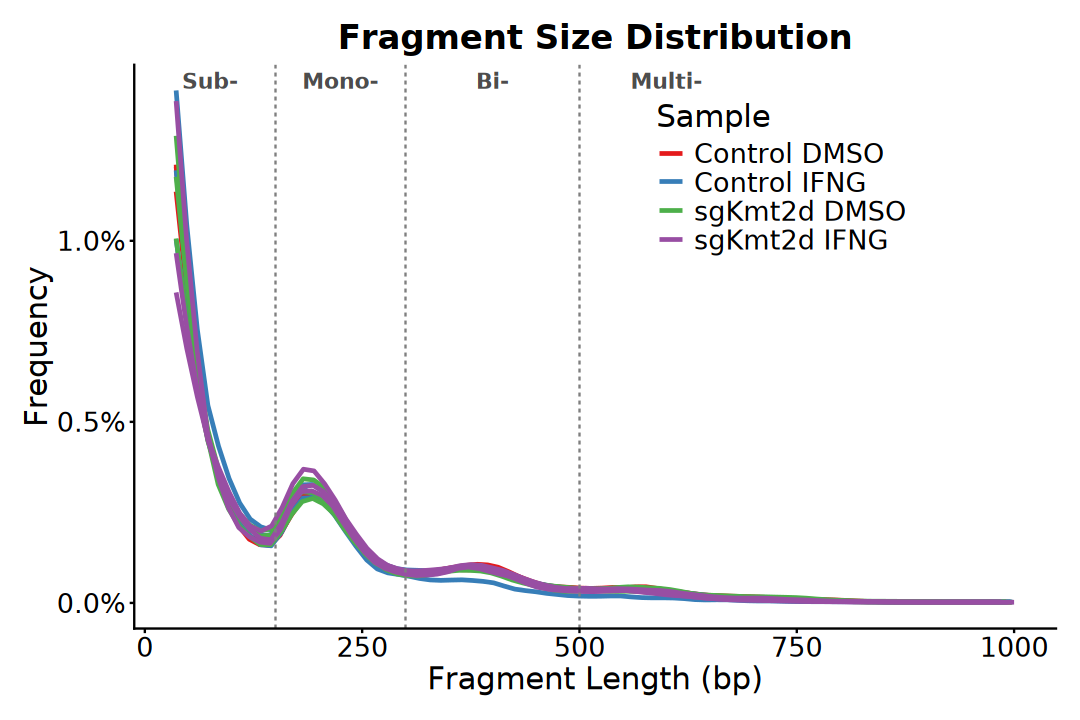

In [14]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(fragment_size, aes(x = Size, y = Freq, group = Sample)) +
    geom_smooth(
        aes(color = Group), formula = y ~ x, method = "loess", 
        na.rm = TRUE, se = FALSE, span = 0.1, linewidth = 1) +
    geom_vline(
        xintercept = c(150, 300, 500), 
        linetype = "dashed", color = "grey50", linewidth = 0.5) +
    annotate(
        "text", x = 75,  y = Inf, label = "Sub-",  vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    annotate(
        "text", x = 225, y = Inf, label = "Mono-", vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    annotate(
        "text", x = 400, y = Inf, label = "Bi-",   vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    annotate(
        "text", x = 600, y = Inf, label = "Multi-", vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    scale_y_continuous(
        limits = c(0, NA), labels = scales::percent_format()) +
    scale_color_brewer(
        palette = "Set1", labels = function(x) gsub("_", " ", x)) +
    labs(
        title = "Fragment Size Distribution", color = "Sample",
        x = "Fragment Length (bp)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "inside",
        legend.position.inside = c(0.7, 0.8),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 3). TSS Enrichment Score

In [15]:
compute_tss_score <- function(
    matrix_file, sample, bs = 10, verbose = TRUE) {

    mat <- matrix_file |> 
        read.table(header = FALSE, sep = "\t", skip = 3) |>
        as.matrix()

    profile <- colMeans(mat, na.rm = TRUE)
    nbins <- length(profile)
    flank_bins <- 100 / bs

    background <- c(
        profile[1:flank_bins], 
        profile[(nbins - flank_bins + 1):nbins]) |> mean()

    norm_profile <- profile / background

    center_bin <- floor(nbins / 2)
    tss_score <- mean(norm_profile[center_bin:(center_bin + 1)])
    if (verbose) {
        message(sample, " TSS Enrichment Score: ", round(tss_score, 2))
    }

    data.frame(
        Position = seq(-2000, 1990, by = bs),
        Signal = profile, 
        Sample = sample, 
        TSS_Score = tss_score, 
        Label = paste0(sample, " (Score: ", round(tss_score, 2), ")"))
}

In [16]:
matrix_files <- file.path(data_dir, "04_output_atacseq", "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

In [17]:
profiles_list <- imap(matrix_files, compute_tss_score)

MA1L_Control_DMSO_rep1 TSS Enrichment Score: 11.62

MA1L_Control_DMSO_rep2 TSS Enrichment Score: 13.05

MA1L_Control_DMSO_rep3 TSS Enrichment Score: 12.39

MA1L_Control_IFNG_rep1 TSS Enrichment Score: 12.85

MA1L_Control_IFNG_rep2 TSS Enrichment Score: 18.59

MA1L_Control_IFNG_rep3 TSS Enrichment Score: 12.32

MA1L_sgKmt2d_DMSO_rep1 TSS Enrichment Score: 11.95

MA1L_sgKmt2d_DMSO_rep2 TSS Enrichment Score: 11.44

MA1L_sgKmt2d_DMSO_rep3 TSS Enrichment Score: 9.8

MA1L_sgKmt2d_IFNG_rep1 TSS Enrichment Score: 11.67

MA1L_sgKmt2d_IFNG_rep2 TSS Enrichment Score: 11.94

MA1L_sgKmt2d_IFNG_rep3 TSS Enrichment Score: 10.7



In [18]:
profile_df <- do.call(rbind, profiles_list) |>
    mutate(Sample = sub("MA1L_(.*)", "\\1", Sample)) |>
    left_join(coldata |> rownames_to_column("Sample"), by = "Sample") |>
    arrange(Group, Replicate) |>
    mutate(
        Sample = forcats::fct_inorder(as.character(Sample)),
        Label = forcats::fct_inorder(as.character(Label)))

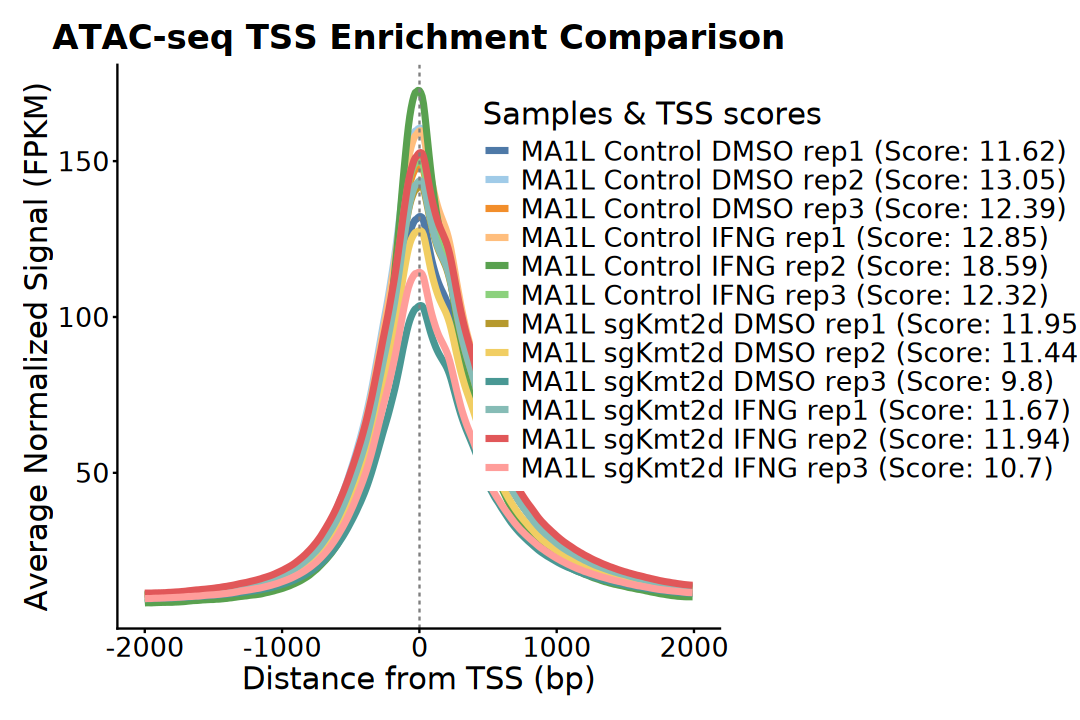

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profile_df, aes(x = Position, y = Signal)) +
    geom_line(aes(color = Label), linewidth = 1.5) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    # scale_color_viridis_d(
    #     option = "viridis", 
    #     labels = function(x) gsub("_", " ", x)) +
    ggthemes::scale_color_tableau(
        palette = "Tableau 20", 
        labels = function(x) gsub("_", " ", x)) +
    labs(
        title = "ATAC-seq TSS Enrichment Comparison",
        color = "Samples & TSS scores",
        x = "Distance from TSS (bp)",
        y = "Average Normalized Signal (FPKM)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 15, 1, 1), "line"),
        legend.position = "inside",
        legend.position.inside = c(1.1, 0.6),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). Number of Peaks

In [20]:
plot_df <- data.frame(sample = names(peaks_list), number = lengths(peaks_list)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

plot_df

,number,Genotype,Treatment,Replicate,Group
,<int>,<fct>,<fct>,<fct>,<fct>
Control_DMSO_rep1,57568,Control,DMSO,rep1,Control_DMSO
Control_DMSO_rep2,58584,Control,DMSO,rep2,Control_DMSO
Control_DMSO_rep3,58042,Control,DMSO,rep3,Control_DMSO
Control_IFNG_rep1,61489,Control,IFNG,rep1,Control_IFNG
Control_IFNG_rep2,66614,Control,IFNG,rep2,Control_IFNG
Control_IFNG_rep3,60988,Control,IFNG,rep3,Control_IFNG
sgKmt2d_DMSO_rep1,61239,sgKmt2d,DMSO,rep1,sgKmt2d_DMSO
sgKmt2d_DMSO_rep2,55800,sgKmt2d,DMSO,rep2,sgKmt2d_DMSO
sgKmt2d_DMSO_rep3,57629,sgKmt2d,DMSO,rep3,sgKmt2d_DMSO


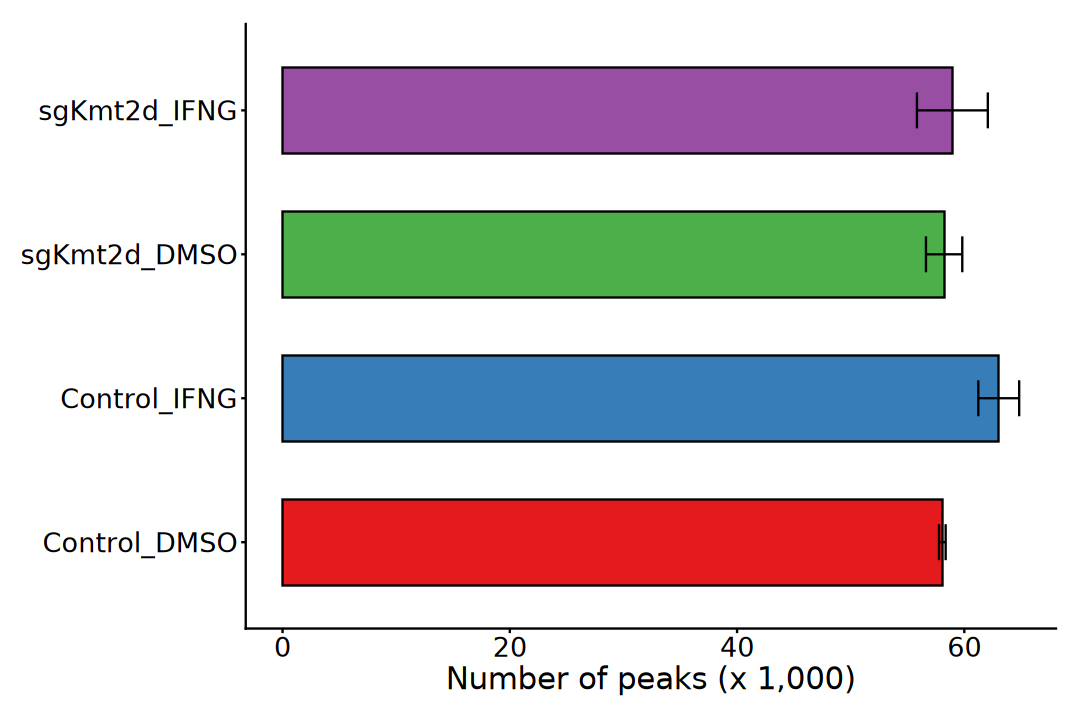

In [21]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = number, fill = Group)) +
    geom_bar(
        stat = "summary", fun = "mean", color = "black", 
        width = 0.6) +
    stat_summary(
        fun.data = mean_se, geom = "errorbar", color = "black", 
        width = 0.25) +
    scale_y_continuous(labels = function(x) x / 1000) +
    scale_fill_brewer(palette = "Set1") +
    scale_color_brewer(palette = "Set1") +
    labs(x = NULL, y = "Number of peaks (x 1,000)") +
    coord_flip() +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Replicate Consistency

In [22]:
# ------------------------------------------------------------------------------
# Function: summarize_peak_overlaps
#
# Description:
# Summarize the overlap composition of peak sets across replicates.
#
# Arguments:
#   peaks_list : named list of GRanges.
#   peaks      : short names used for display and ordering.
#                Default: rep1, rep2, ..., repN.
# ------------------------------------------------------------------------------
summarize_peak_overlaps <- function(
    peaks_list, peaks = paste0("rep", seq_along(peaks_list))) {

    names(peaks_list) <- peaks

    comb_levels <- unlist(
        lapply(seq_along(peaks), function(i) {
            combn(peaks, i, FUN = paste, collapse = "&")
        }), use.names = FALSE)

    ol <- lapply(peaks_list, function(gr) {
            names(gr) <- gr$name
            return(gr)
        }) |>
            ChIPpeakAnno::findOverlapsOfPeaks()

    ol$venn_cnt[, c(names(peaks_list), "Counts"), drop = FALSE] |>
        as.data.frame(stringsAsFactors = FALSE) |>
        dplyr::rename_with(~ peaks, .cols = names(peaks_list)) |>
        dplyr::rowwise() |>
        dplyr::mutate(
            Combination = {
                present <- peaks[c_across(dplyr::all_of(peaks)) == 1]
                if (length(present) == 0) {
                    NA_character_
                } else {
                    paste(present, collapse = "&")
                }
            }
        ) |>
        dplyr::ungroup() |>
        dplyr::mutate(
            Combination = factor(Combination, levels = comb_levels)) |>
        dplyr::filter(!is.na(Combination)) |>
        dplyr::select(Combination, Counts) |>
        as.data.frame()
}

In [23]:
replicate_peak_df <- dplyr::bind_rows(
    Control_DMSO = summarize_peak_overlaps(
        peaks_list[
            coldata |> dplyr::filter(Group == "Control_DMSO") |> rownames()]
    ),
    Control_IFNG = summarize_peak_overlaps(
        peaks_list[
            coldata |> dplyr::filter(Group == "Control_IFNG") |> rownames()]
    ),
    sgKmt2d_DMSO = summarize_peak_overlaps(
        peaks_list[
            coldata |> dplyr::filter(Group == "sgKmt2d_DMSO") |> rownames()]
    ),
    sgKmt2d_IFNG = summarize_peak_overlaps(
        peaks_list[
            coldata |> dplyr::filter(Group == "sgKmt2d_IFNG") |> rownames()]
    ),
    .id = "Group"
)

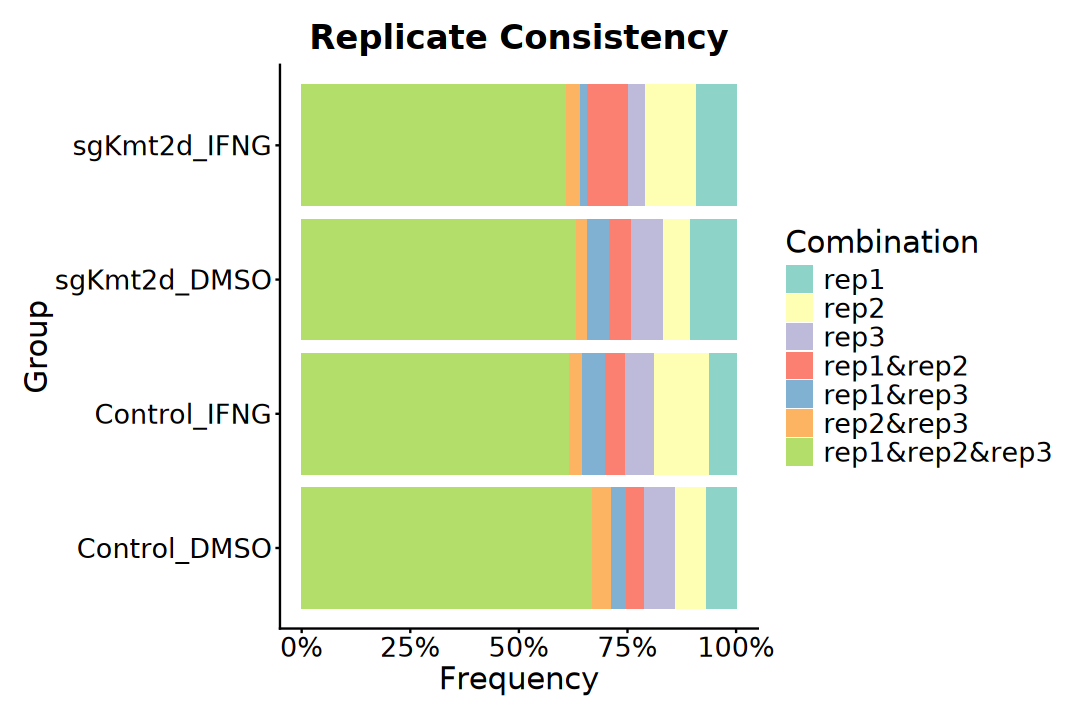

In [24]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(replicate_peak_df, aes(x = Group, y = Counts)) +
    geom_bar(aes(fill = Combination), stat = "identity", position = "fill") +
    scale_y_continuous(labels = scales::percent_format()) + 
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Replicate Consistency", x = "Group", y = "Frequency") +
    coord_flip() +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Genome-wide Landscape

## 1). Global Signal

In [25]:
bin_means_df <- file.path(
    data_dir, "04_output_atacseq", "09_count", "bins_10kb.counts.tsv") |>
    read.table(header = TRUE, sep = "\t", comment.char = "") |>
    dplyr::rename(chr = X.chr) |>
    mutate(pos = paste0(chr, ":", start, "-", end)) |>
    select(-chr, -start, -end) |>
    column_to_rownames("pos") |>
    # filter(if_any(everything(), ~ var(.x, na.rm = TRUE) > 0))
    slice_max(
        order_by = apply(as.matrix(pick(everything())), 1, var), n = 2000
    )

bin_means_df[1:6, 1:2]

,MA1L_Control_DMSO_rep1,MA1L_Control_DMSO_rep2
,<dbl>,<dbl>
chr17:39838130-39848130,56231,45576
JH584304.1:50000-60000,20724,19695
JH584304.1:60000-70000,13505,13231
chr17:39848130-39858130,8223,6523
chr8:84976260-84986260,7391,6637
chr11:3190000-3200000,6812,5631


In [26]:
cor_mat <- cor(bin_means_df, method = "spearman")

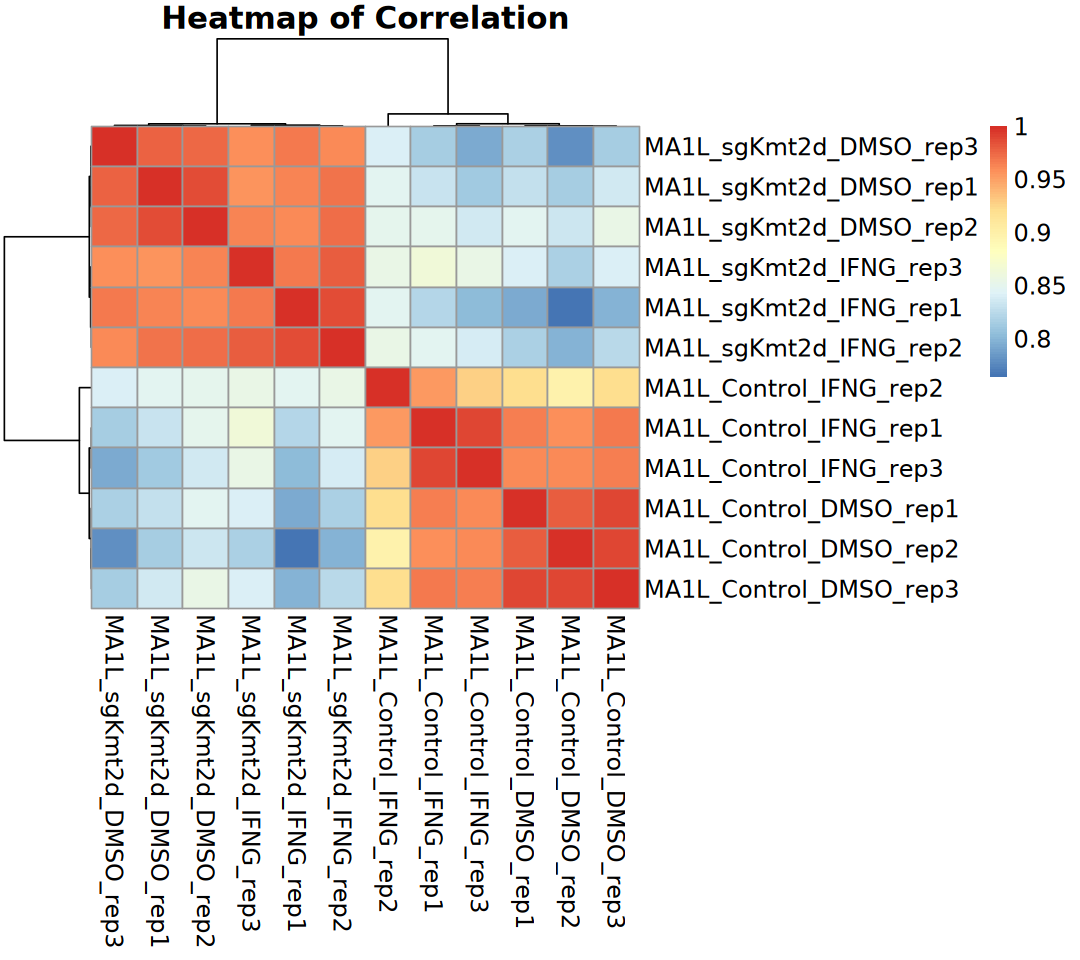

In [27]:
options(repr.plot.width = 9, repr.plot.height = 8)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation", 
    clustering_distance_cols = "correlation", 
    main = "Heatmap of Correlation", fontsize = 14, 
    show_colnames = TRUE, show_rownames = TRUE)

In [28]:
pca_df <- bin_means_df |> t() |>
    prcomp(center = TRUE, scale. = TRUE)

per_var <- round(pca_df$sdev^2 / sum(pca_df$sdev^2) * 100, 2)

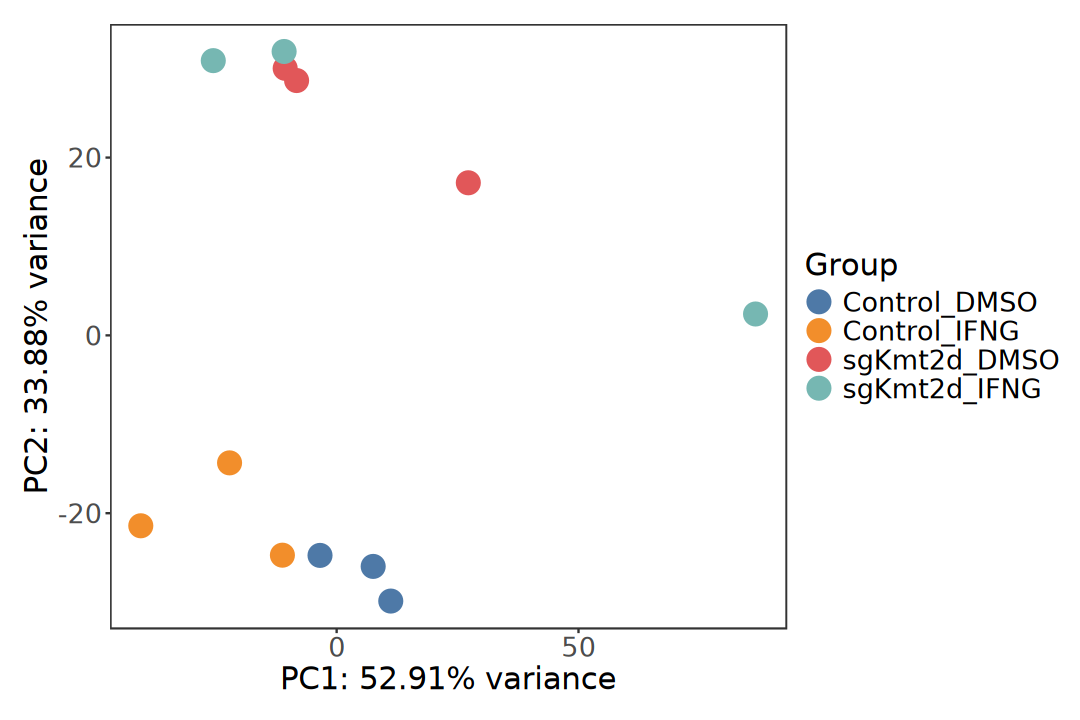

In [29]:
options(repr.plot.width = 9, repr.plot.height = 6)

pca_df$x |> as.data.frame() |> 
    rownames_to_column(var = "Sample") |>
    mutate(Sample = sub("MA1L_(.*)", "\\1", Sample)) |>
    left_join(coldata |> rownames_to_column("Sample"), by = "Sample") |>
ggplot(aes(PC1, PC2)) +
    geom_point(aes(color = Group), size = 6) +
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    xlab(paste0("PC1: ", per_var[1], "% variance")) +
    ylab(paste0("PC2: ", per_var[2], "% variance")) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Metagene Profile

### a). deepTools

In [30]:
matrix_files <- file.path(data_dir, "04_output_atacseq", "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("MA1L_(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

In [31]:
compute_matrix_mean <- function(file, sample) {
    read.table(file, header = FALSE, sep = "\t", skip = 3) |>
        as.matrix() |> colMeans(na.rm = TRUE)
}

In [32]:
profiles_list <- imap(matrix_files, compute_matrix_mean)

In [33]:
profiles_tss <- do.call(cbind, profiles_list) |>
    as.data.frame() |>
    mutate(Position = seq(-2000, 2000, length.out = 400)) |>
    pivot_longer(-Position, names_to = "Sample", values_to = "Signal") |>
    left_join(coldata |> rownames_to_column("Sample"), by = "Sample")

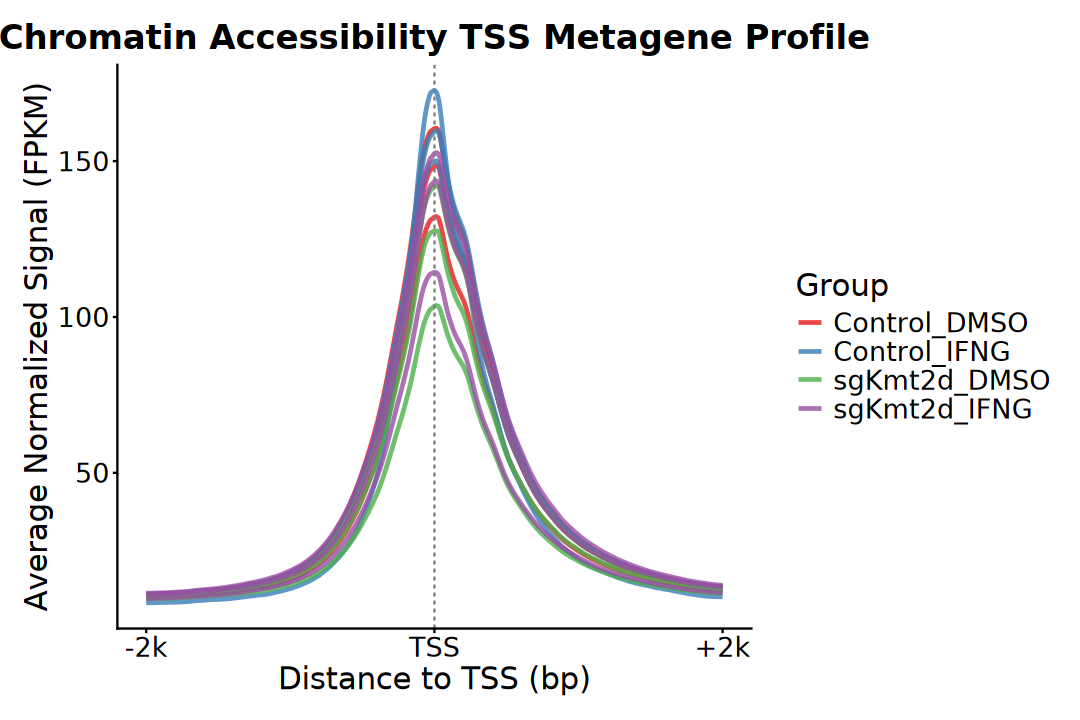

In [34]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_tss, aes(Position, Signal)) +
    geom_line(
        aes(color = Group, group = Sample), alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        breaks = c(-2000, 0, 2000), labels = c("-2k", "TSS", "+2k")) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "Chromatin Accessibility TSS Metagene Profile", 
        x = "Distance to TSS (bp)",
        y = "Average Normalized Signal (FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing = unit(2, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.box.margin = margin(l = 10),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### b). EnrichedHeatmap

In [35]:
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [36]:
GENES <- gtf |> subset(
    type == "gene" & gene_type == "protein_coding", 
    select = c("gene_id", "gene_name", "gene_type")
)

In [37]:
# ~ 16 minutes
gene_mat_list <- lapply(
    signals_list, normalizeToMatrix, GENES, value_column = "score", 
    mean_mode = "w0", extend = 2000, w = 50, smooth = FALSE, 
    target_ratio = 0.4, background = NA)

In [38]:
gene_mat_merged_list <- lapply(paste0("rep", 1:3), function(idx) {
    rbind.normalizedMatrix(
        gene_mat_list[[paste0("Control_DMSO_", idx)]],
        gene_mat_list[[paste0("Control_IFNG_", idx)]],
        gene_mat_list[[paste0("sgKmt2d_DMSO_", idx)]],
        gene_mat_list[[paste0("sgKmt2d_IFNG_", idx)]]
    )
})

names(gene_mat_merged_list) <- paste0("rep", 1:3)

In [39]:
partition <- c(
    "Control_DMSO", "Control_IFNG", "sgKmt2d_DMSO", "sgKmt2d_IFNG") |>
    rep(each = length(GENES))

partition_cols <- c(
    Control_DMSO  = "#1B9E77", 
    Control_IFNG = "#66C2A5", 
    sgKmt2d_DMSO = "#7570B3", 
    sgKmt2d_IFNG = "#A6A1D0"
)

partition_lgd <- Legend(
    at = names(partition_cols), title = "Group",
    legend_gp = gpar(fill = partition_cols))

In [40]:
max_signal <- unlist(gene_mat_list, use.names = FALSE) |>
    abs() |> quantile(0.99, na.rm = TRUE)

unified_cols <- circlize::colorRamp2(
    c(0, max_signal), c("#F5F5F5", "#FF3F56"))

signal_lgd <- Legend(col_fun = unified_cols, title = "FPKM")

In [41]:
ht_list <- lapply(names(gene_mat_merged_list), function(idx) {
    EnrichedHeatmap(
        gene_mat_merged_list[[idx]], 
        name = idx, 
        column_title = idx, 
        col = unified_cols, 
        width = unit(4, "cm"), 
        show_row_names = FALSE, 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"), 
        show_heatmap_legend = FALSE,
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = partition_cols), 
                axis_param = list(gp = gpar(fontsize = 10))), 
            height = unit(3, "cm"), 
            show_legend = FALSE), 
        use_raster = TRUE)
})

In [42]:
ht_list <- Heatmap(
    partition, name = "Group", col = partition_cols, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE) +
    Reduce(`+`, ht_list)

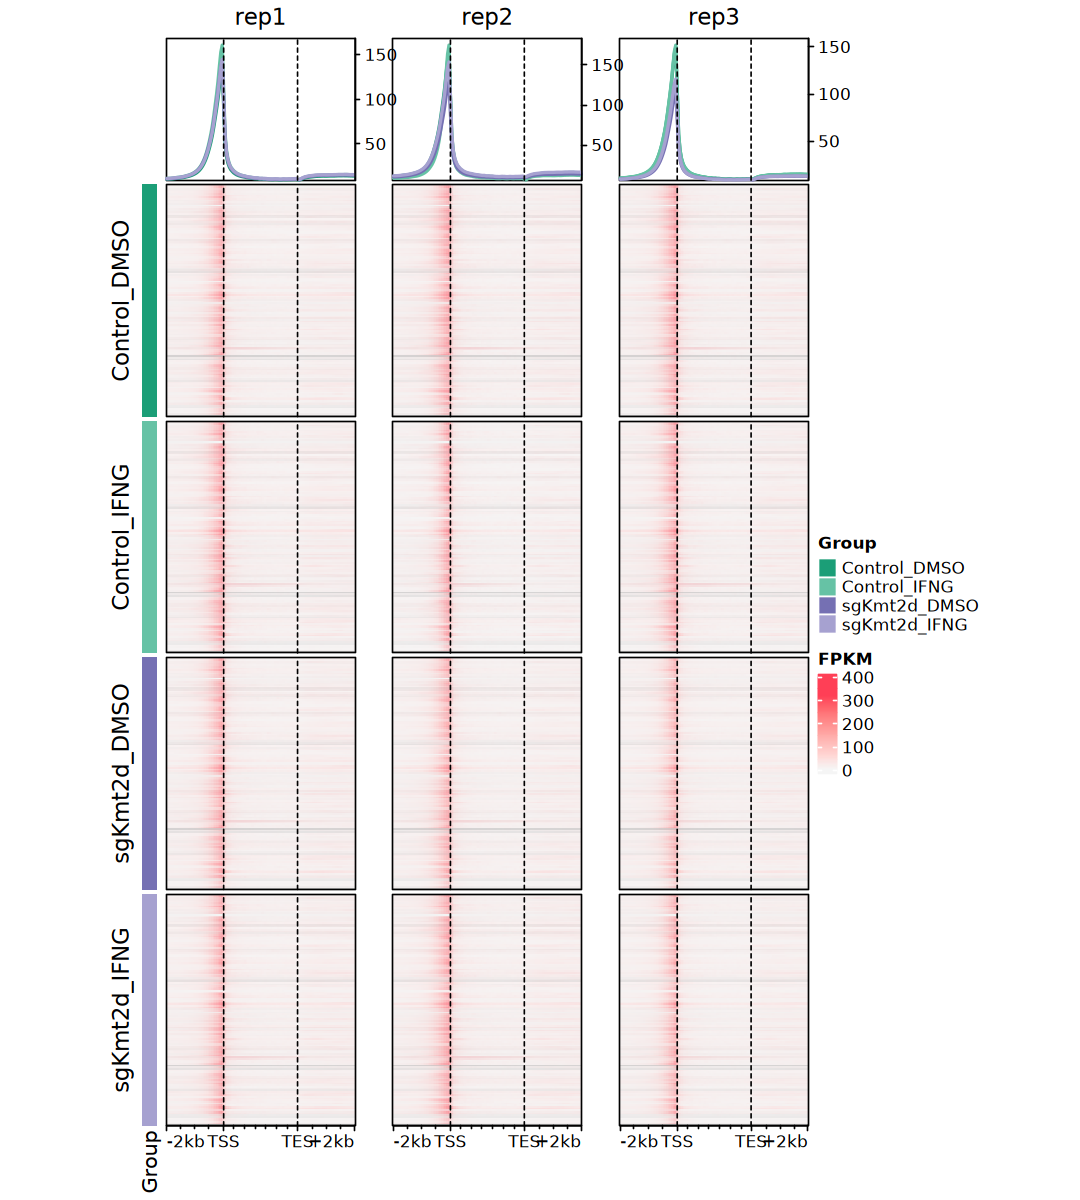

In [43]:
options(repr.plot.width = 9, repr.plot.height = 10)

draw(
    ht_list, split = partition, heatmap_legend_side = "right", 
    annotation_legend_list = list(partition_lgd, signal_lgd),
    ht_gap = unit(c(2, rep(8, length(gene_mat_merged_list))), "mm"))

# 5. Peak Annotation

In [44]:
suppressPackageStartupMessages(library(ChIPseeker))

In [45]:
peaks_anno_list <- lapply(
    peaks_list, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "transcript", verbose = FALSE, 
    genomicAnnotationPriority = c(
        "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
        "Downstream", "Intergenic")
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>."


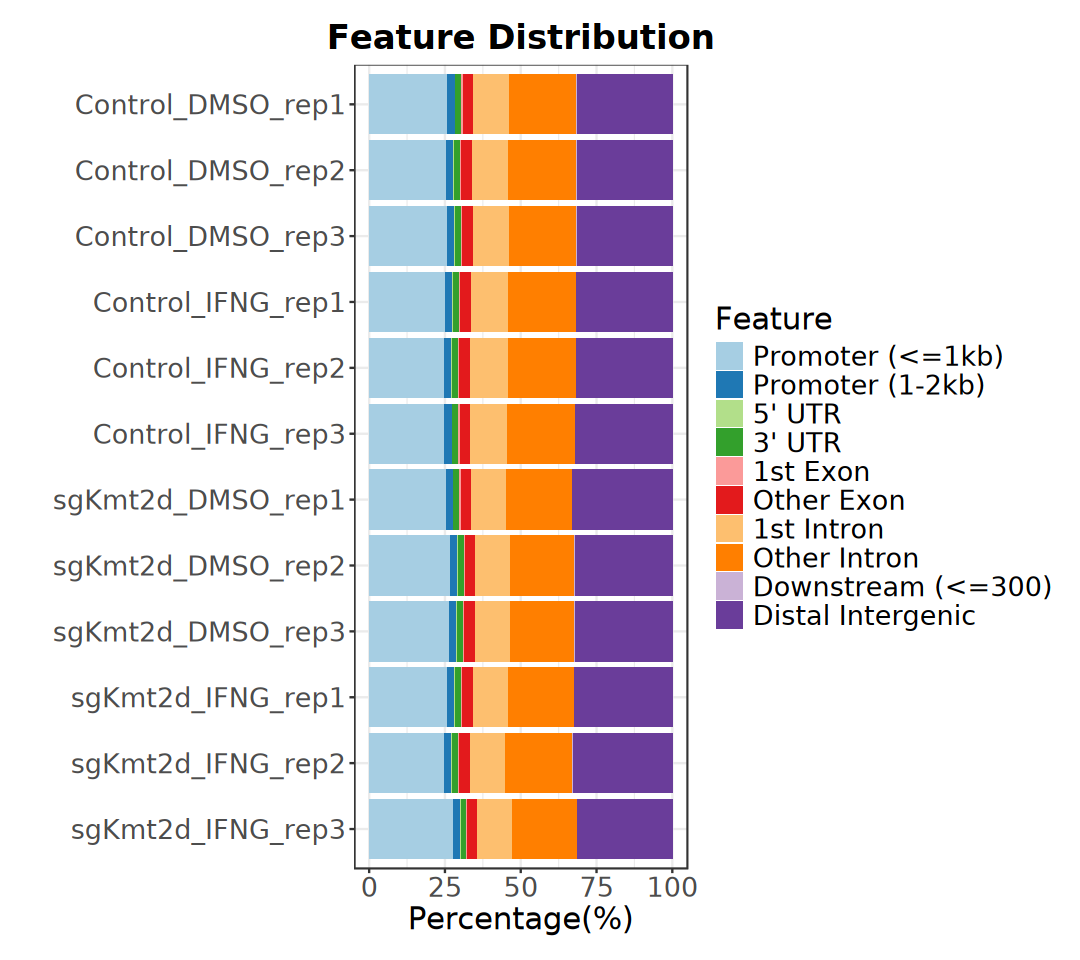

In [46]:
options(repr.plot.width = 9, repr.plot.height = 8)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 6. Differential Accessibility Regions

In [47]:
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))

In [48]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

In [49]:
raw_counts <- file.path(
    data_dir, "04_output_atacseq", "09_count", "MA1L_consensus.counts.tsv") |>
    read_tsv(comment = "", show_col_types = FALSE) |>
    rename_with(~ stringr::str_remove_all(.x, "^#|'")) |>
    unite("pos", chr, start, end, sep = "_") |>
    column_to_rownames("pos") |>
    rename_with(~ stringr::str_remove(.x, "^MA1L_")) |>
    select(rownames(coldata)) |>
    as.matrix()

dim(raw_counts)
raw_counts[1:6, 1:4]

[1] 79814    12

,Control_DMSO_rep1,Control_DMSO_rep2,Control_DMSO_rep3,Control_IFNG_rep1
chr3_40510472_40510973,69,65,62,47
chr3_40523201_40523702,131,141,131,148
chr3_40531356_40531857,66,68,64,81
chr3_40540548_40541049,150,184,174,191
chr1_79640203_79640704,69,81,75,73
chr1_79644010_79644511,17,14,6,15


In [50]:
dds <- DESeqDataSetFromMatrix(
    count = raw_counts, colData = coldata, design = ~ Treatment + Genotype)
dds

converting counts to integer mode



class: DESeqDataSet 
dim: 79814 12 
metadata(1): version
assays(1): counts
rownames(79814): chr3_40510472_40510973 chr3_40523201_40523702 ...
  chr1_51288702_51289203 chr1_51289851_51290352
rowData names(0):
colnames(12): Control_DMSO_rep1 Control_DMSO_rep2 ... sgKmt2d_IFNG_rep2
  sgKmt2d_IFNG_rep3
colData names(4): Genotype Treatment Replicate Group

In [51]:
dds <- estimateSizeFactors(dds)

sf <- sizeFactors(dds)

paste(names(sf), round(sf, 4), sep = ": ") |> cat(sep = "\n")

Control_DMSO_rep1: 1.02
Control_DMSO_rep2: 0.9786
Control_DMSO_rep3: 0.9782
Control_IFNG_rep1: 1.1392
Control_IFNG_rep2: 0.9592
Control_IFNG_rep3: 1.0553
sgKmt2d_DMSO_rep1: 1.0614
sgKmt2d_DMSO_rep2: 0.9462
sgKmt2d_DMSO_rep3: 1.0711
sgKmt2d_IFNG_rep1: 1.0479
sgKmt2d_IFNG_rep2: 1.1342
sgKmt2d_IFNG_rep3: 0.7221


In [52]:
# Library sizes were estimated using the total number of uniquely mapped reads.

library_sizes <- file.path(
    data_dir, "04_output_atacseq", "09_count", "MA1L_consensus.reads.tsv") |>
    read.table(header = TRUE, row.names = 1)

rownames(library_sizes) <- stringr::str_remove(
    rownames(library_sizes), "^MA1L_"
)
library_sizes <- library_sizes[colnames(dds), ]

# Geometric mean
sf <- library_sizes / exp(mean(log(library_sizes)))
names(sf) <- colnames(dds)

sizeFactors(dds) <- sf

paste(names(sf), round(sf, 4), sep = ": ") |> cat(sep = "\n")


Control_DMSO_rep1: 1.0135
Control_DMSO_rep2: 0.9975
Control_DMSO_rep3: 0.9837
Control_IFNG_rep1: 1.1554
Control_IFNG_rep2: 1.0383
Control_IFNG_rep3: 1.0638
sgKmt2d_DMSO_rep1: 1.043
sgKmt2d_DMSO_rep2: 0.9239
sgKmt2d_DMSO_rep3: 1.0146
sgKmt2d_IFNG_rep1: 1.0337
sgKmt2d_IFNG_rep2: 1.1213
sgKmt2d_IFNG_rep3: 0.6953


In [53]:
dds <- DESeq(dds)
resultsNames(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"                   "Treatment_IFNG_vs_DMSO"     
[3] "Genotype_sgKmt2d_vs_Control"

In [54]:
res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 79814 with nonzero total read count
adjusted p-value < 0.05
LFC > 1.00 (up)    : 2385, 3%
LFC < -1.00 (down) : 842, 1.1%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



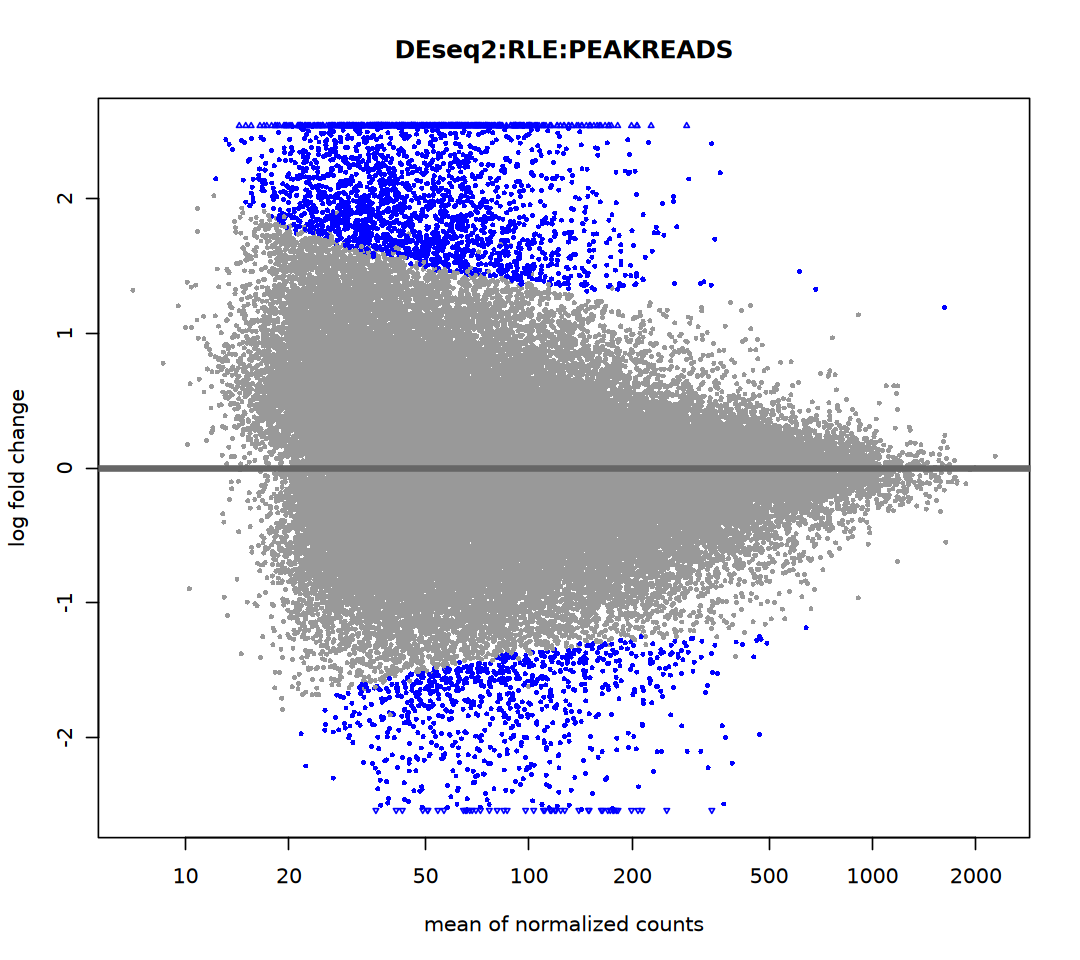

In [55]:
options(repr.plot.width = 9, repr.plot.height = 8)

plotMA(res, main = "DEseq2:RLE:PEAKREADS", alpha = p_cutoff)

In [56]:
deseq2_result <- res |> as.data.frame() |> 
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Gain",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Loss",
            TRUE ~ "NS") |> 
            factor(levels = c("Gain", "Loss", "NS"))) |>
    rownames_to_column(var = "peak_id") |>
    separate(
        peak_id, into = c("chr", "start", "end"), 
        sep = "_", remove = TRUE) |>
    GRanges()

deseq2_result

GRanges object with 79814 ranges and 7 metadata columns:
          seqnames            ranges strand |  baseMean     logFC     lfcSE
             <Rle>         <IRanges>  <Rle> | <numeric> <numeric> <numeric>
      [1]     chr3 40510472-40510973      * |   48.9858 -0.431560 0.1631791
      [2]     chr3 40523201-40523702      * |  124.9705 -0.241881 0.1017004
      [3]     chr3 40531356-40531857      * |   96.1390  0.746313 0.1170558
      [4]     chr3 40540548-40541049      * |  165.6779 -0.124971 0.0927247
      [5]     chr1 79640203-79640704      * |   50.3244 -1.057440 0.1634765
      ...      ...               ...    ... .       ...       ...       ...
  [79810]     chr1 51250275-51250776      * |  168.2761  0.556677  0.107623
  [79811]     chr1 51264958-51265459      * |  134.9563  0.753400  0.104621
  [79812]     chr1 51286820-51287321      * |   55.9448  0.306657  0.149901
  [79813]     chr1 51288702-51289203      * |  196.5182  2.196033  0.104763
  [79814]     chr1 51289851-512

In [57]:
res_tab <- table(deseq2_result$result)

message(
    "Differential accessibility peaks summary (DEseq2):\n",
    "---------------------------------------------------\n",
    "Gain (higher accessibility) : ", res_tab["Gain"], "\n",
    "Loss (lower accessibility)  : ", res_tab["Loss"], "\n",
    "Not significant             : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

Differential accessibility peaks summary (DEseq2):
---------------------------------------------------
Gain (higher accessibility) : 2385
Loss (lower accessibility)  : 842
Not significant             : 76587
---------------------------------------------------



In [58]:
dar_peaks <- list(
    Gain = deseq2_result[deseq2_result$result == "Gain", ], 
    Loss = deseq2_result[deseq2_result$result == "Loss", ])

In [59]:
dar_peaks <- lapply(
    dar_peaks, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "transcript", verbose = FALSE, 
    genomicAnnotationPriority = c(
        "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
        "Downstream", "Intergenic")
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


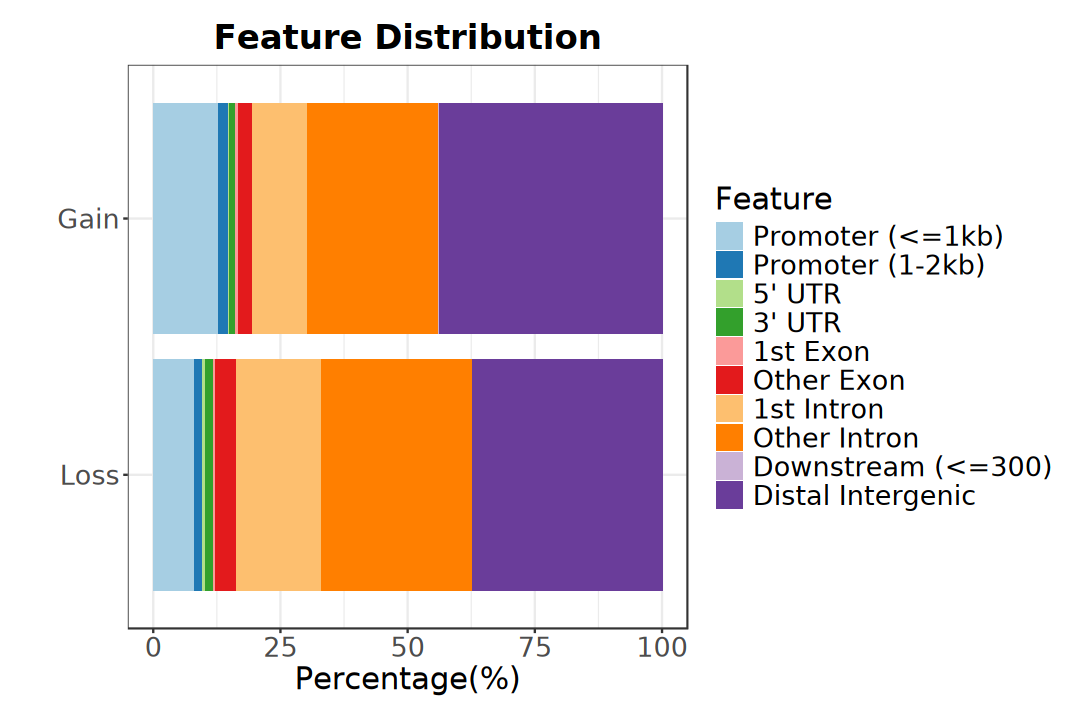

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(dar_peaks) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [61]:
peaks_anno_list <- lapply(dar_peaks, function(anno) {
    anno@anno |> 
    as.data.frame() |>
    mutate(
        Category = case_when(
            grepl("Promoter", annotation) ~ "Promoter",
            grepl("UTR|Exon", annotation) ~ "Exon",
            grepl("Intron", annotation) ~ "Intron",
            grepl("Downstream|Intergenic", annotation) ~ "Intergenic",
            TRUE ~ as.character(annotation)
        )) |> 
    as("GRanges")
})

In [62]:
promoter_genes <- lapply(peaks_anno_list, function(anno) {
    anno |> as.data.frame() |>
        filter(Category == "Promoter", !is.na(geneId), geneId != "") |>
        distinct(geneId) |>
        pull(geneId) |>
        unique()
})

# 7. Function Analysis

In [63]:
suppressPackageStartupMessages(library(ChIPseeker))
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [64]:
add_ENTREZID <- function(
    query_ids, orgdb, fromType = "ENSEMBL", toType = c("SYMBOL", "ENTREZID"), 
    ignoreVersion = FALSE) {

    if(fromType == "ENSEMBL" & ignoreVersion) {
        query_ids <- sub("\\..*$", "", query_ids) |> unique()
    }

    gene_map <- clusterProfiler::bitr(
        query_ids, OrgDb = orgdb, fromType = fromType, toType = toType, 
        drop = FALSE)

    idx <- match(query_ids, gene_map[[fromType]])

    res <- data.frame(
        fromType = query_ids, stringsAsFactors = FALSE)

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }

    return(res)
}

In [65]:
promoter_genes <- lapply(promoter_genes, add_ENTREZID,
    orgdb = org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), 
    ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(query_ids, OrgDb = orgdb, fromType = fromType, :
"20.77% of input gene IDs are fail to map..."
'select()' returned 1:1 mapping between keys and columns

Warning message in clusterProfiler::bitr(query_ids, OrgDb = orgdb, fromType = fromType, :
"24.68% of input gene IDs are fail to map..."


In [66]:
genes_list <- lapply(promoter_genes, \(x) x$SYMBOL |> na.omit() |> unique())

all_symbols <- AnnotationDbi::keys(org.Mm.eg.db, keytype = "SYMBOL")

In [67]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, universe = all_symbols, 
    OrgDb = org.Mm.eg.db, ont = "ALL", keyType = 'SYMBOL', 
    pAdjustMethod = "BH", pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

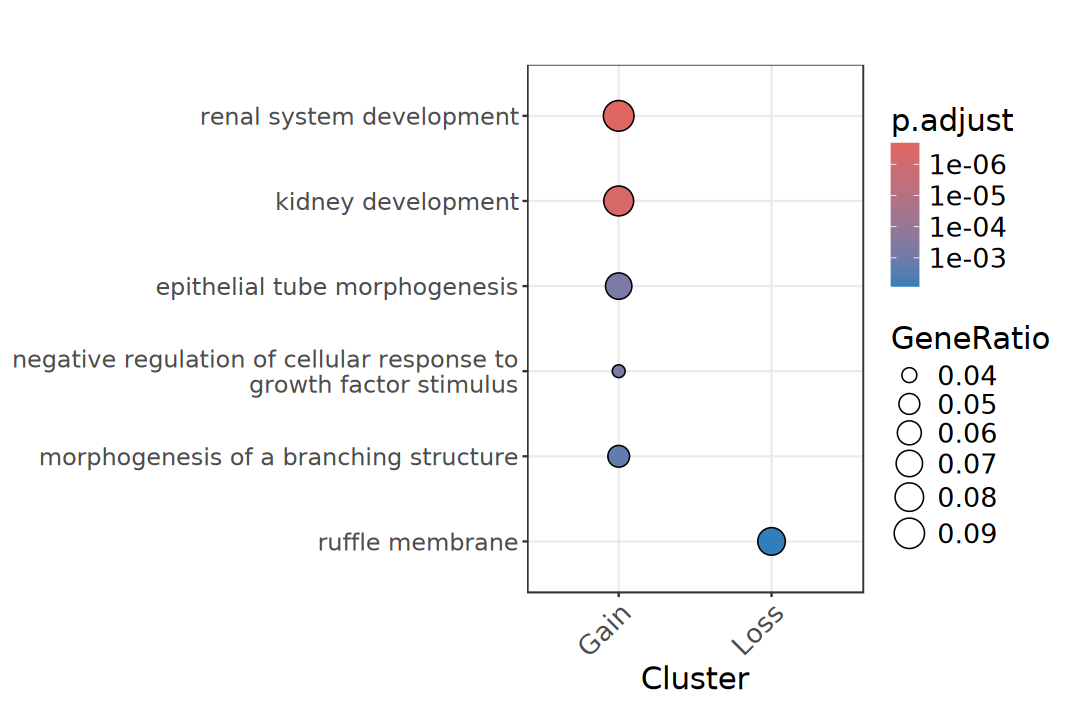

In [68]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ego_compare, showCategory = 5, label_format = 50) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [69]:
genes_list <- lapply(promoter_genes, \(x) x$ENTREZID |> na.omit() |> unique())

all_entrezid <- AnnotationDbi::keys(org.Mm.eg.db, keytype = "ENTREZID")

In [70]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, universe = all_entrezid, 
    organism = "mmu", 
    pAdjustMethod = "BH", pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

Warning message in compareCluster(geneCluster = genes_list, fun = enrichKEGG, universe = all_entrezid, :
"No enrichment found in any of gene cluster, please check your input..."


In [71]:
# options(repr.plot.width = 9, repr.plot.height = 6)

# dotplot(ekegg_compare, showCategory = 5, label_format = 40) +
#     theme_bw() +
#     theme(
#         plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
#         plot.margin = unit(c(1, 1, 1, 1), "line"),
#         legend.title = element_text(size = 18), 
#         legend.text = element_text(size = 16),
#         axis.title = element_text(size = 18), 
#         axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
#         axis.text.y = element_text(size = 14))

# * Reference